## 1. Write a Python script using pandas and scikit-learn to load a dataset, perform a 70/30 train/test split, and apply standard scaling (StandardScaler) to the feature columns.

In [1]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = load_wine(as_frame=True).frame
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape, X_test_scaled.shape)

(124, 13) (54, 13)


## 2. Using matplotlib and seaborn, write a function that takes a pandas DataFrame and a column name as input, and plots both a boxplot and a scatter plot to visually identify outliers and distribution patterns.

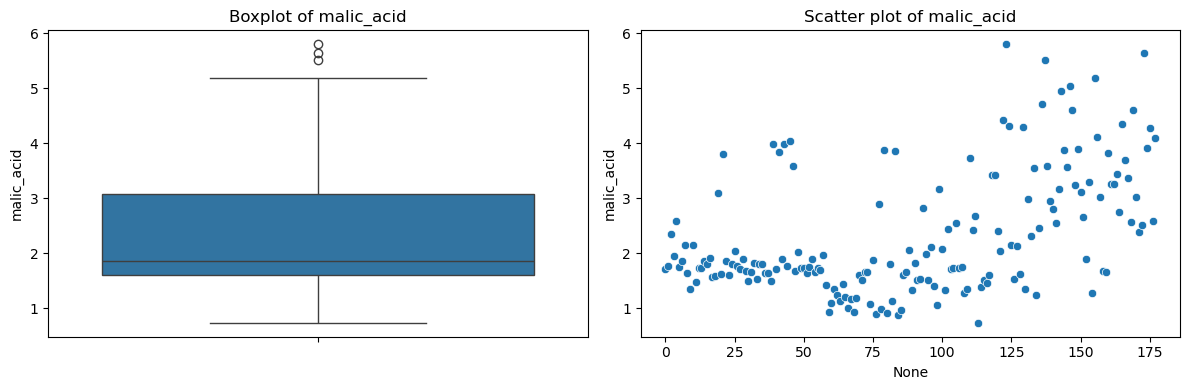

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_outliers(df, column):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(y=df[column], ax=axes[0])
    axes[0].set_title(f"Boxplot of {column}")
    sns.scatterplot(x=df.index, y=df[column], ax=axes[1])
    axes[1].set_title(f"Scatter plot of {column}")
    plt.tight_layout()
    plt.show()

plot_outliers(df, "malic_acid")

## 3. Implement a linear regression model using scikit-learn's LinearRegression on a housing dataset. Calculate and print the Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R² score on the test set.

In [3]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

housing = fetch_california_housing(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    housing.data, housing.target, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("R2  :", r2_score(y_test, y_pred))

RMSE: 0.7455813830127763
MAE : 0.5332001304956555
R2  : 0.575787706032451


## 4. Write a Python program to load the Iris dataset, train a LogisticRegression model, and output the predicted classes for the test dataset.

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=42)

clf = LogisticRegression(max_iter=200).fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Predicted classes:", y_pred)

Predicted classes: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0 0 0 2 1 1 0 0]


## 5. Implement a K-Nearest Neighbors (KNN) classifier with n_neighbors=5. After training and testing the model, write the code to compute and display its confusion matrix using scikit-learn utilities.

[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


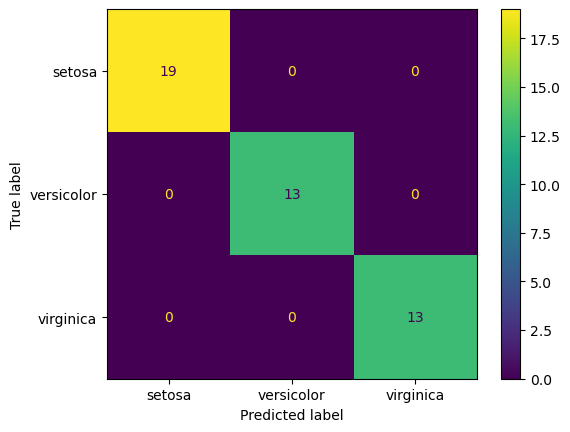

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
y_pred = knn.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot()
plt.show()

## 6. Write a script to compare a single Decision Tree Classifier against a Random Forest Classifier on a binary classification dataset. Print the accuracy score of both models to determine which performed better.

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
rf = RandomForestClassifier(random_state=42).fit(X_train, y_train)

dt_acc = accuracy_score(y_test, dt.predict(X_test))
rf_acc = accuracy_score(y_test, rf.predict(X_test))
print("Decision Tree:", dt_acc)
print("Random Forest:", rf_acc)
print("Better model:", "Random Forest" if rf_acc > dt_acc else "Decision Tree")

Decision Tree: 0.9415204678362573
Random Forest: 0.9707602339181286
Better model: Random Forest


## 7. Given a set of true labels and predicted labels, write code to manually calculate or use scikit-learn to extract the precision, recall, and F1-score for a specific target class without using the full classification_report.

In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_true = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1]
cls = 1

# Manual
TP = sum(t == cls and p == cls for t, p in zip(y_true, y_pred))
FP = sum(t != cls and p == cls for t, p in zip(y_true, y_pred))
FN = sum(t == cls and p != cls for t, p in zip(y_true, y_pred))

precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
print("Manual :", precision, recall, f1)

# sklearn
print("sklearn:", precision_score(y_true, y_pred, pos_label=cls),
      recall_score(y_true, y_pred, pos_label=cls),
      f1_score(y_true, y_pred, pos_label=cls))


Manual : 0.8333333333333334 0.7142857142857143 0.7692307692307692
sklearn: 0.8333333333333334 0.7142857142857143 0.7692307692307693


## 8. Implement a 5-fold cross-validation routine using KFold and cross_val_score to evaluate the stability of a Ridge regression model on a continuous target variable.

In [8]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score

X, y = load_diabetes(return_X_y=True)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(Ridge(alpha=1.0), X, y, cv=kf, scoring="r2")
print("Fold scores:", scores)
print("Mean:", scores.mean())
print("Std :", scores.std())

Fold scores: [0.41915293 0.45201323 0.33243928 0.50045558 0.34243974]
Mean: 0.40930015081282817
Std : 0.06420078318020656


## 9. Write a Python snippet utilizing GridSearchCV to find the optimal hyperparametersfor a Random Forest Classifier. Search across n_estimators ([50, 100, 200]) and max_depth ([None, 10, 20]).

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

param_grid = {"n_estimators": [50, 100, 200], "max_depth": [None, 10, 20]}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV score:", grid.best_score_)
print("Test score:", grid.score(X_test, y_test))

Best params: {'max_depth': None, 'n_estimators': 200}
Best CV score: 0.9522151898734176
Test score: 0.9707602339181286


## 10. Create a complete scikit-learn Pipeline that chains a MinMaxScaler preprocessing step with a LogisticRegression classifier, then fit the entire pipeline on training data and evaluate it on test data.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

pipe = Pipeline([
    ("scaler", MinMaxScaler()),
    ("clf", LogisticRegression(max_iter=1000))
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9649122807017544
